**Proyecto final:**

**Análisis de señales ECG y detección de arritmias Proyecto**

**Presentado por:**

Karly Tarazona, Luis Montoya

1.	De los artículos: 

- https://www.nature.com/articles/s41746-023-00966-w  
- https://www.nature.com/articles/s41598-020-59821-7
- https://www.sciencedirect.com/science/article/pii/S2405844024032316

Para cada artículo hacer un diagrama de flujo de las metodologías usadas en los artículos

Explicar en sus palabras las metodologías desarrolladas

2.	Cargar el archivo Diagnostics.xlsx y realizar un análisis estadístico general de los datos. Desde la información en la base de datos resolver las siguientes preguntas 

○ ¿Qué tipo de arritmias son más prevalentes?  

○ ¿Hay arritmias que son más prevalentes para un género específico?

○ ¿Hay arritmias que son más prevalentes para una edad? 

○ Los algoritmos de aprendizaje se basan en usar la mayor cantidad de datos posibles que sean comparables, ¿Qué rango de edades y arritmias de la base de datos entregada considera que debe usar para entrenar algoritmos de aprendizaje? 

○ ¿Hay coincidencia entre lo encontrado en literatura y lo encontrado en la base de datos? 

○ ¿Qué otros análisis propone desde la base de datos? 


Registros: 10646


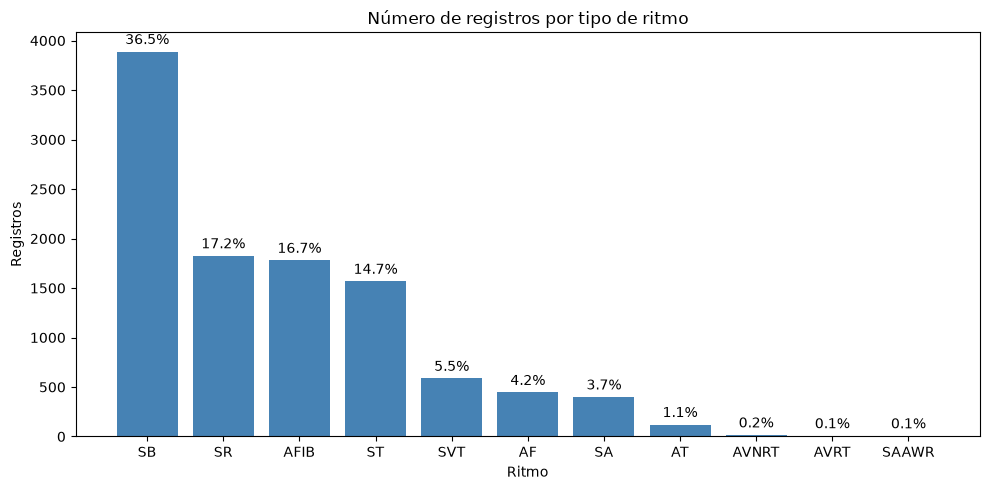

In [11]:
import pandas as pd
import matplotlib.pyplot as plt


df = pd.read_excel("Diagnostics.xlsx")

print("Registros:", len(df))

conteo = df["Rhythm"].value_counts()

# Calcular porcentajes
porcentaje = conteo / conteo.sum() * 100

# Crear gráfico
fig, ax = plt.subplots(figsize=(10, 5))

barras = ax.bar(
    conteo.index,
    conteo.values,
    color="steelblue"
)

# Agregar porcentajes encima de las barras
ax.bar_label(
    barras,
    labels=[f"{p:.1f}%" for p in porcentaje],
    padding=3,
    fontsize=10
)

ax.set_title("Número de registros por tipo de ritmo")
ax.set_xlabel("Ritmo")
ax.set_ylabel("Registros")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


1. ¿Qué arritmias son más prevalentes?
Los ritmos más frecuentes son:

Bradicardia sinusal (SB): 36,5 %.

Ritmo sinusal (SR): 17,2 %.

Fibrilación auricular (AFIB): 16,7 %.

Taquicardia sinusal (ST): 14,7 %.


Siguen SVT (5,5 %), AF (4,2 %), SA (3,8 %) y AT (1,1 %). 

Hay tres clases casi vacías: AVNRT (16 registros), AVRT (8) y SAAWR (7).


In [30]:
genero = pd.crosstab(df["Rhythm"], df["Gender"])

porcentaje_genero = (df["Gender"].value_counts(normalize=True) * 100).round(2)

print(porcentaje_genero)

genero

Gender
MALE      55.95
FEMALE    44.05
Name: proportion, dtype: float64


Gender,FEMALE,MALE
Rhythm,,
AF,188,257
AFIB,739,1041
AT,57,64
AVNRT,12,4
AVRT,3,5
SA,176,223
SAAWR,6,1
SB,1408,2481
SR,1024,802


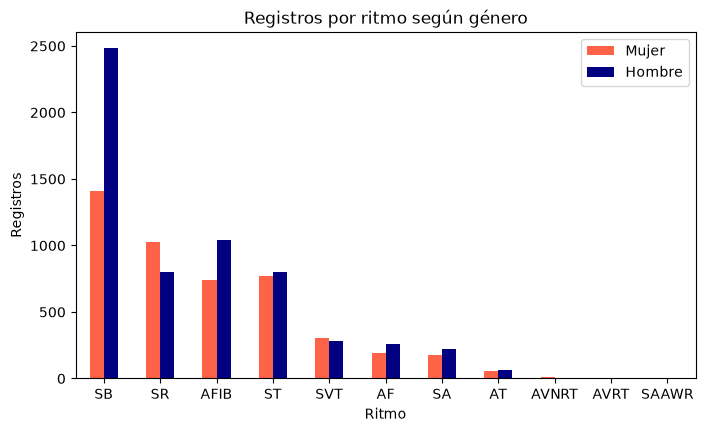

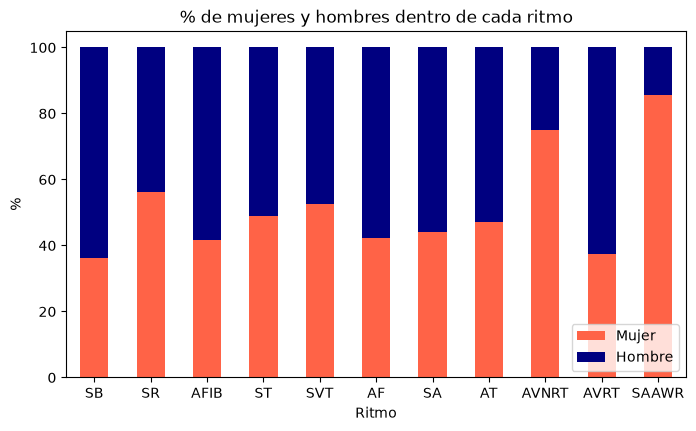

In [19]:

genero.loc[conteo.index].plot(kind="bar", color=["tomato", "navy"], figsize=(8, 4.5))
plt.title("Registros por ritmo según género")
plt.xlabel("Ritmo")
plt.ylabel("Registros")
plt.legend(["Mujer", "Hombre"])
plt.xticks(rotation=0)
plt.show()

# En porcentaje dentro de cada ritmo
porc = pd.crosstab(df["Rhythm"], df["Gender"], normalize="index") * 100
porc.loc[conteo.index].plot(kind="bar", stacked=True, color=["tomato", "navy"], figsize=(8, 4.5))
plt.title("% de mujeres y hombres dentro de cada ritmo")
plt.xlabel("Ritmo")
plt.ylabel("%")
plt.legend(["Mujer", "Hombre"], loc="lower right")
plt.xticks(rotation=0)
plt.show()

In [5]:
promedio_edad = df["PatientAge"].mean()

print(f"Promedio de edad general: {promedio_edad:.1f} años")

mediana_edad = df["PatientAge"].median()

print(f"Mediana de edad: {mediana_edad:.1f} años")

df.groupby("Rhythm")["PatientAge"].agg(["count", "mean", "median", "std", "min", "max"]).round(1).loc[conteo.index]





Promedio de edad general: 59.2 años
Mediana de edad: 62.0 años


,count,mean,median,std,min,max
Rhythm,,,,,,
SB,3889,58.3,60.0,14.0,10,98
SR,1826,54.4,55.0,16.3,4,95
AFIB,1780,73.4,75.0,11.1,30,98
ST,1568,54.6,57.0,21.1,4,96
SVT,587,55.6,56.0,18.5,4,96
AF,445,71.1,72.0,13.5,21,97
SA,399,34.7,29.0,23.0,4,93
AT,121,65.7,71.0,19.3,8,94
AVNRT,16,57.9,59.0,17.3,27,84


In [6]:

# Crear grupos de edad
df["GrupoEdad"] = pd.cut(
    df["PatientAge"],
    bins=[0, 20, 40, 60, 80, 120],
    labels=[
        "0-20",
        "21-40",
        "41-60",
        "61-80",
        "81+"
    ],
    include_lowest=True
)

# Cantidad de registros por ritmo y grupo de edad
tabla_edades = pd.crosstab(
    df["Rhythm"],
    df["GrupoEdad"]
)

print(tabla_edades)

GrupoEdad  0-20  21-40  41-60  61-80  81+
Rhythm                                   
AF            0     13     76    244  112
AFIB          0     10    218   1022  530
AT            6      8     17     67   23
AVNRT         0      3      6      4    3
AVRT          0      1      2      5    0
SA          143    110     73     65    8
SAAWR         2      1      1      1    2
SB           40    364   1639   1664  182
SR           36    335    751    613   91
ST          117    277    474    532  168
SVT          15    109    221    178   64


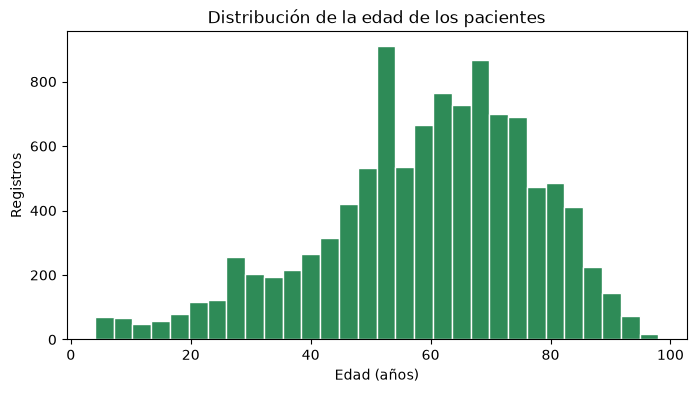

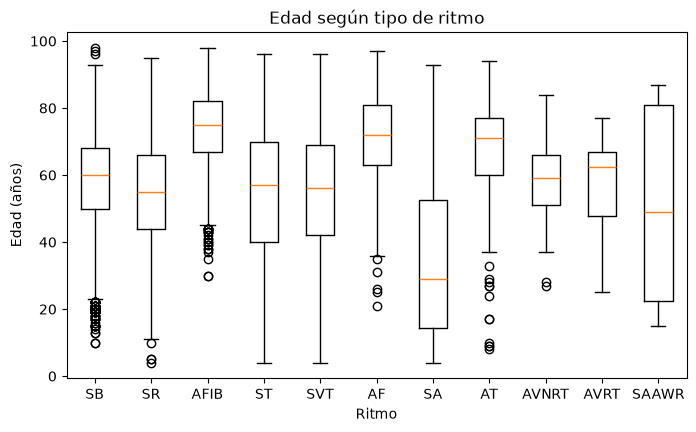

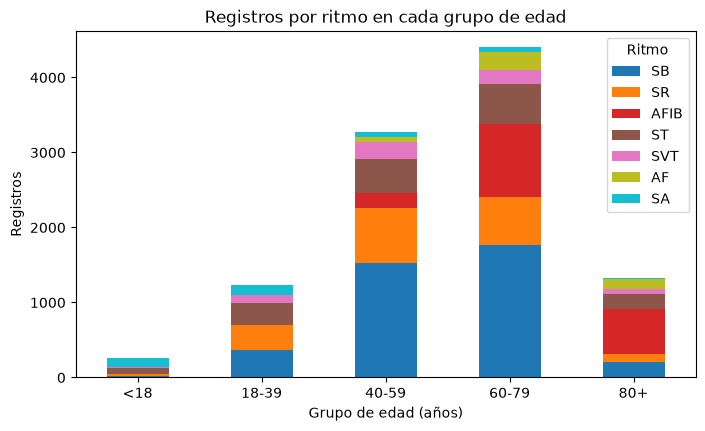

In [20]:
plt.figure(figsize=(8, 4))
plt.hist(df["PatientAge"], bins=30, color="seagreen", edgecolor="white")
plt.title("Distribución de la edad de los pacientes")
plt.xlabel("Edad (años)")
plt.ylabel("Registros")
plt.show()


# Edad por ritmo
datos = [df.loc[df["Rhythm"] == r, "PatientAge"] for r in conteo.index]
plt.figure(figsize=(8, 4.5))
plt.boxplot(datos, tick_labels=conteo.index)
plt.title("Edad según tipo de ritmo")
plt.xlabel("Ritmo")
plt.ylabel("Edad (años)")
plt.show()

# Ritmos por grupo de edad
df["GrupoEdad"] = pd.cut(df["PatientAge"], bins=[0, 17, 39, 59, 79, 120],
                         labels=["<18", "18-39", "40-59", "60-79", "80+"])
pd.crosstab(df["GrupoEdad"], df["Rhythm"])[conteo.index[:7]].plot(kind="bar", stacked=True, colormap="tab10", figsize=(8, 4.5))
plt.title("Registros por ritmo en cada grupo de edad")
plt.xlabel("Grupo de edad (años)")
plt.ylabel("Registros")
plt.legend(title="Ritmo", bbox_to_anchor=(1, 1))
plt.xticks(rotation=0)
plt.show()

AFIB: edad media 73 años. Casi todos los casos están por encima de los 60.
AF (aleteo): edad media 71 años.
SA (arritmia sinusal): mediana de 29 años, claramente la más joven. Esto es esperable, porque en jóvenes suele ser fisiológica.
SB, SR, ST y SVT: medias de 54 a 58 años.